# Predicting a stock's daily direction from the first two hours of trading
### Re-validating our KRX competition model, and finding a leak in our own result

**Context.** For the 1st KRX Financial Big Data Competition (2022), our team built models that use minute-level KOSPI market data from 09:00 to 11:00 to predict whether a stock will **close above its opening price** that day. Our best model (CatBoost) reached 0.83 accuracy on a random 70/30 split.

**What this notebook does.** After the competition, I re-checked that result with three questions:

1. **Does it hold up out of time?** Train on 2019–2021, test on 2022, instead of shuffling all days together.
2. **Does it beat a trivial rule?** Compare every model against "predict *up* if the price at 11:00 is above the open."
3. **Was every feature actually available at 11:00?** Audit the features that came from end-of-day data.

**Short answer.** The models generalize across time, but on features that are truly available at 11:00 they only match the trivial rule (≈0.80). The extra accuracy in the competition came from one feature that quietly included the day's closing price.

**Data.** KRX (Korea Exchange) market data provided to competition participants: 2019-01 to 2022-07, about 655,000 stock-days. The team's engineered feature tables and the daily price file are used here; they are not redistributed in this repository. The original competition notebook (in Korean) is in `notebooks/original/`.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

DATA_DIR = '../data/'
SEED = 9

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

## 1. Load the data

The source files use Korean column names, so they are renamed to English right after loading.

In [2]:
COLUMNS = {
    # identifiers and labels
    '거래일자': 'date', '종목코드': 'ticker', '종목명': 'name',
    '종가-시가상승여부': 'target_close_above_open',
    '11시_9시변동률(%)': 'return_0900_1100_pct', '11시9시변동률레이블': 'up_at_1100',
    '회전율(%)': 'turnover_pct',
    # supply and demand
    '외국인순매수(도)금액': 'foreign_net_buy_value', '외국인순매수(도)거래량': 'foreign_net_buy_volume',
    '외국인체결강도(%)': 'foreign_buy_sell_strength',
    # information asymmetry (order book, frequency, volume)
    '전량가중평균지정가/종가': 'depth_weighted_quote_to_price', 'HS역선택비용/호가단위': 'adverse_selection_cost_per_tick',
    '평균호가스프레드/호가단위': 'quoted_spread_per_tick', '평균비율스프레드': 'relative_spread',
    '주문수량기준깊이': 'depth_by_quantity', '주문빈도기준취소율': 'cancel_rate_by_count',
    '주문량기준취소율': 'cancel_rate_by_volume', '종목별거래횟수기준매수매도불균형': 'trade_imbalance_by_count',
    '종목별거래량기준매수매도불균형': 'trade_imbalance_by_volume', '주문횟수기준주문불균형': 'order_imbalance_by_count',
    # trend and position
    '일중강도/거래량': 'intraday_intensity', 'DailyVolumeIndex/거래량(%)': 'daily_volume_index',
    'TRIN(Inverted)': 'trin_inverted', 'PPP': 'pivot_point_position', 'MFI': 'money_flow_index',
    '분당변동률(%)_기하': 'return_1min_geomean', '10분당변동률(%)_기하': 'return_10min_geomean',
}

def load(path):
    d = pd.read_csv(path, encoding='cp949', index_col=0)
    return d.rename(columns=COLUMNS)[list(COLUMNS.values())]

train_raw = load(DATA_DIR + '최종train(2019_2021).csv')   # team's feature table, 2019-2021
test_raw = load(DATA_DIR + '최종test(2022).csv')           # team's feature table, 2022-01 to 2022-07

for label, d in [('train', train_raw), ('test', test_raw)]:
    print(f"{label}: {len(d):,} stock-days, {d['date'].min()}-{d['date'].max()}, "
          f"share closing above open = {d['target_close_above_open'].mean():.3f}")

train: 544,123 stock-days, 20190103-20211230, share closing above open = 0.439
test: 110,881 stock-days, 20220104-20220729, share closing above open = 0.454


## 2. Features

The competition model used 22 features in three groups. This feature table is an earlier version of the final one, so two columns are adjusted to match the final definitions and one feature is missing (it is examined in Section 6).

| Group | Features |
|---|---|
| Supply and demand | foreign net buying (value, volume), foreign buy/sell strength, signed turnover |
| Information asymmetry | spreads, adverse-selection cost, market depth, cancellation rates, trade and order imbalances |
| Trend and position | intraday intensity, daily volume index, TRIN, pivot-point position, money flow index, 1-min and 10-min returns |

- **Signed turnover** = turnover × (+1 if the price rose from 09:00 to 11:00, otherwise −1).
- **TRIN** is bucketed as in the final notebook (≥3 → 2, >0.5 → 1, else 0).
- **Trading value / market cap** is not in this table (see Section 6).

Preferred shares and SPACs are removed, as in the original analysis.

In [3]:
FEATURES = [
    'foreign_net_buy_value', 'foreign_net_buy_volume', 'foreign_buy_sell_strength', 'signed_turnover_pct',
    'depth_weighted_quote_to_price', 'adverse_selection_cost_per_tick', 'quoted_spread_per_tick', 'relative_spread',
    'depth_by_quantity', 'cancel_rate_by_count', 'cancel_rate_by_volume', 'trade_imbalance_by_count',
    'trade_imbalance_by_volume', 'order_imbalance_by_count',
    'intraday_intensity', 'daily_volume_index', 'trin_inverted', 'pivot_point_position', 'money_flow_index',
    'return_1min_geomean', 'return_10min_geomean',
]
TARGET = 'target_close_above_open'
EXCLUDED_NAME_SUFFIXES = ('우', '우B', '우(전환)', '1호', '2호')   # Korean suffixes for preferred shares and SPACs

def prepare(d):
    d = d[~d['name'].str.endswith(EXCLUDED_NAME_SUFFIXES)].copy()
    d['signed_turnover_pct'] = d['turnover_pct'] * np.where(d['up_at_1100'] == 1, 1, -1)
    d['trin_inverted'] = np.select([d['trin_inverted'] >= 3, d['trin_inverted'] > 0.5], [2, 1], 0)
    d = d.replace([np.inf, -np.inf], np.nan).dropna(subset=FEATURES + [TARGET])
    return d.reset_index(drop=True)

train_df, test_df = prepare(train_raw), prepare(test_raw)
print(f'train: {len(train_df):,} rows | test: {len(test_df):,} rows | features: {len(FEATURES)}')

train: 544,123 rows | test: 110,881 rows | features: 21


## 3. A trivial baseline

Stocks that rise in the first two hours often finish the day above their open. Before training anything, here is how far that observation alone goes: **predict *up* if the 11:00 price is above the open.**

In [4]:
def baseline_predict(d):
    return (d['up_at_1100'] == 1).astype(int)

for label, d in [('2019-2021', train_df), ('2022', test_df)]:
    p = baseline_predict(d)
    print(f'{label}: accuracy {accuracy_score(d[TARGET], p):.4f} | F1 {f1_score(d[TARGET], p):.4f}')

2019-2021: accuracy 0.7996 | F1 0.7657
2022: accuracy 0.8004 | F1 0.7757


The rule alone is right about **80%** of the time, in both periods. Any model has to be judged against this number, not against 50%.

## 4. Random split vs. time split

The models and hyperparameters are the ones selected in the competition. Two choices differ from the original notebook:

- **Winsorizing** (clipping the top and bottom 0.5%) uses thresholds computed on the training set only, so the test set does not influence preprocessing.
- The **neural network** from the original notebook is left out; it did not outperform the tree models.

In [5]:
def make_models():
    return {
        'Logistic Regression': LogisticRegression(C=0.8, penalty='l1', solver='liblinear', random_state=SEED),
        'Decision Tree': DecisionTreeClassifier(max_depth=7, max_features='sqrt', min_samples_split=4, random_state=SEED),
        'Random Forest': RandomForestClassifier(max_depth=5, n_estimators=100, min_samples_split=4,
                                                random_state=SEED, n_jobs=-1),
        'XGBoost': XGBClassifier(n_estimators=100, max_depth=7, eval_metric='logloss', random_state=SEED, n_jobs=-1),
        'CatBoost': CatBoostClassifier(random_state=SEED, verbose=False, thread_count=-1),
    }

def winsorize(X_train, X_test, q=0.005):
    lo, hi = X_train.quantile(q), X_train.quantile(1 - q)
    return X_train.clip(lo, hi, axis=1), X_test.clip(lo, hi, axis=1)

def run(train, test, split_name):
    X_tr, X_te = winsorize(train[FEATURES], test[FEATURES])
    y_tr, y_te = train[TARGET], test[TARGET]
    p = baseline_predict(test)
    rows = [{'split': split_name, 'model': 'Baseline rule', 'accuracy': accuracy_score(y_te, p), 'f1': f1_score(y_te, p)}]
    fitted = {}
    for name, model in make_models().items():
        model.fit(X_tr, y_tr)
        p = model.predict(X_te)
        rows.append({'split': split_name, 'model': name, 'accuracy': accuracy_score(y_te, p), 'f1': f1_score(y_te, p)})
        fitted[name] = model
    return pd.DataFrame(rows), fitted

In [6]:
# (a) Competition setup: all days pooled, random 70/30 split
pooled = pd.concat([train_df, test_df], ignore_index=True)
idx_tr, idx_te = train_test_split(pooled.index, test_size=0.3, random_state=SEED)
res_random, _ = run(pooled.loc[idx_tr], pooled.loc[idx_te], 'Random 70/30')

# (b) Out-of-time: train on 2019-2021, test on 2022
res_time, fitted = run(train_df, test_df, 'Train 2019-21, test 2022')

results = pd.concat([res_random, res_time])
summary = results.pivot(index='model', columns='split', values='accuracy')
summary = summary[['Random 70/30', 'Train 2019-21, test 2022']]
MODEL_ORDER = ['Baseline rule', 'Logistic Regression', 'Decision Tree', 'Random Forest', 'XGBoost', 'CatBoost']
summary = summary.loc[MODEL_ORDER]
summary['vs. baseline (2022)'] = summary['Train 2019-21, test 2022'] - summary.loc['Baseline rule', 'Train 2019-21, test 2022']
summary.round(4)

split,Random 70/30,"Train 2019-21, test 2022",vs. baseline (2022)
model,,,
Baseline rule,0.8000,0.8004,0.0000
Logistic Regression,0.7713,0.7718,-0.0286
Decision Tree,0.7987,0.7997,-0.0008
Random Forest,0.7999,0.8002,-0.0002
XGBoost,0.7989,0.7991,-0.0013
CatBoost,0.8007,0.8006,0.0002


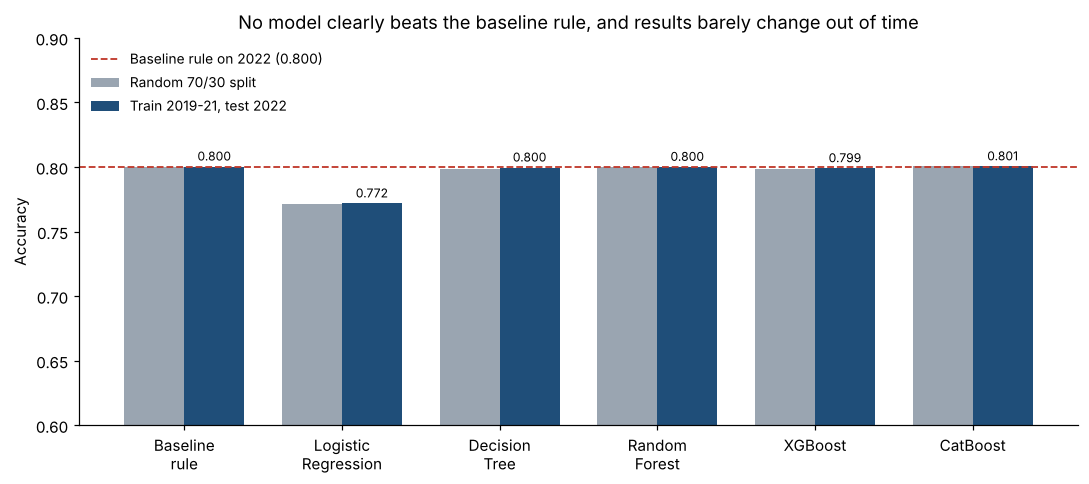

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.5))
x, w = np.arange(len(MODEL_ORDER)), 0.38
ax.bar(x - w/2, summary['Random 70/30'], w, label='Random 70/30 split', color='#9aa5b1')
bars = ax.bar(x + w/2, summary['Train 2019-21, test 2022'], w, label='Train 2019-21, test 2022', color='#1f4e79')
base = summary.loc['Baseline rule', 'Train 2019-21, test 2022']
ax.axhline(base, color='#c0392b', ls='--', lw=1.2, label=f'Baseline rule on 2022 ({base:.3f})')
ax.bar_label(bars, fmt='%.3f', fontsize=8, padding=2)
ax.set_xticks(x, ['Baseline\nrule', 'Logistic\nRegression', 'Decision\nTree', 'Random\nForest', 'XGBoost', 'CatBoost'])
ax.set_ylim(0.6, 0.9)
ax.set_ylabel('Accuracy')
ax.set_title('No model clearly beats the baseline rule, and results barely change out of time')
ax.legend(loc='upper left', fontsize=9, frameon=False)
plt.tight_layout()
plt.show()

Two findings:

- **The time split costs almost nothing.** Every model scores within about 0.1 percentage points of its random-split result, so pooling days in the competition did not inflate the results.
- **No model clearly beats the rule.** The best model, CatBoost, is just 0.0002 above the baseline on 2022.

## 5. What the best model actually learned

If CatBoost added real information, it would disagree with the baseline on some stocks and be right more often than not when it does.

In [8]:
cat = fitted['CatBoost']
_, X_test_w = winsorize(train_df[FEATURES], test_df[FEATURES])
pred_model = cat.predict(X_test_w).astype(int)
pred_rule = baseline_predict(test_df).values
y = test_df[TARGET].values

disagree = pred_model != pred_rule
print(f'CatBoost disagrees with the rule on {disagree.sum():,} of {len(y):,} stock-days ({disagree.mean():.1%}).')
print(f'On those, CatBoost is right {np.mean(pred_model[disagree] == y[disagree]):.1%} of the time '
      f'and the rule {np.mean(pred_rule[disagree] == y[disagree]):.1%}.')

CatBoost disagrees with the rule on 2,672 of 110,881 stock-days (2.4%).
On those, CatBoost is right 50.3% of the time and the rule 49.7%.


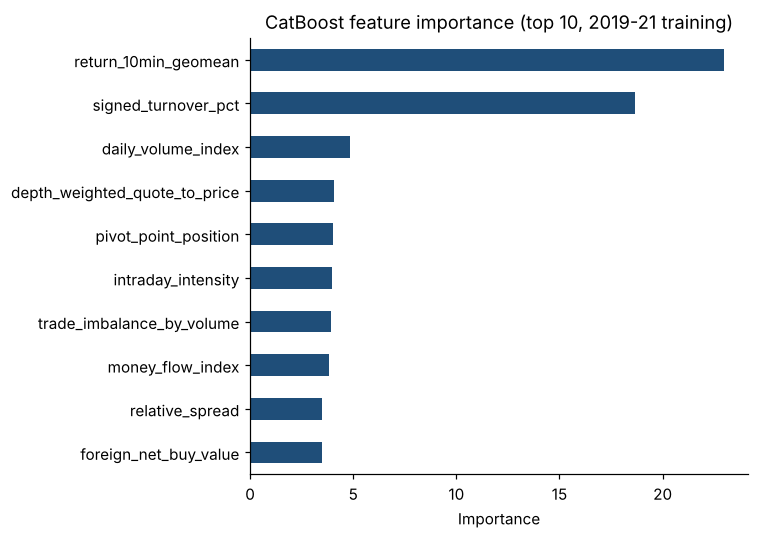

In [9]:
importance = pd.Series(cat.get_feature_importance(), index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
importance.tail(10).plot.barh(ax=ax, color='#1f4e79')
ax.set_title('CatBoost feature importance (top 10, 2019-21 training)')
ax.set_xlabel('Importance')
plt.tight_layout()
plt.show()

CatBoost departs from the rule on only about 2% of stock-days and is right on roughly half of them, which is a coin flip. Its two most important features, the 10-minute return and signed turnover, both encode the same morning direction the rule uses. In effect, the model learned the rule.

## 6. Why the competition model scored 0.83: a look-ahead leak

The final competition model had one more feature: **trading value / market cap**, the second most important feature in that model. It was computed as total trading value from 09:00 to 11:00 divided by the `market_cap` column of the **daily** price file.

The question is which price that market cap is based on.

In [10]:
DAILY_COLUMNS = {'거래일자': 'date', '종목코드': 'ticker', '시가': 'open', '종가': 'close',
                 '기준가': 'reference_price', '상장주식수': 'shares_outstanding', '시가총액': 'market_cap'}
daily = pd.read_csv(DATA_DIR + 'df_일별데이터.csv', usecols=list(DAILY_COLUMNS)).rename(columns=DAILY_COLUMNS)

for price in ['close', 'open', 'reference_price']:
    share = (daily['market_cap'] == daily[price] * daily['shares_outstanding']).mean()
    print(f'market_cap == {price:15s} x shares_outstanding : {share:6.1%} of rows')

market_cap == close           x shares_outstanding : 100.0% of rows
market_cap == open            x shares_outstanding :   5.8% of rows
market_cap == reference_price x shares_outstanding :   7.9% of rows


The daily market cap equals **that day's closing price × shares outstanding** in every row. The closing price is set at 15:30, four and a half hours after the prediction is made. Written out, the feature is roughly

> trading value / market cap ≈ turnover × (average morning price / **closing price**)

and because signed turnover is also in the model, the two together let it read off how the morning price compares with the close, which is almost exactly the target.

The raw minute-level data is not available here, so the feature is approximated: the average morning price is taken as (open + 11:00 price) / 2. The leak-free version divides by the **previous day's** reference price, which is known before the market opens.

In [11]:
def add_value_to_market_cap(d):
    d = d.merge(daily[['date', 'ticker', 'open', 'close', 'reference_price']], on=['date', 'ticker'], how='left')
    price_1100 = d['open'] * (1 + d['return_0900_1100_pct'] / 100)
    avg_morning_price = (d['open'] + price_1100) / 2
    d['value_to_mcap_same_day_close'] = d['turnover_pct'] * avg_morning_price / d['close']             # as in the competition
    d['value_to_mcap_prev_close'] = d['turnover_pct'] * avg_morning_price / d['reference_price']       # known at 11:00
    return d

train_m, test_m = add_value_to_market_cap(train_df), add_value_to_market_cap(test_df)
base_2022 = accuracy_score(test_df[TARGET], baseline_predict(test_df))

rows = []
for label, extra in [('21 features available at 11:00', []),
                     ("+ value / market cap (same-day close, as in competition)", ['value_to_mcap_same_day_close']),
                     ("+ value / market cap (previous day's close)", ['value_to_mcap_prev_close'])]:
    cols = FEATURES + extra
    X_tr, X_te = winsorize(train_m[cols], test_m[cols])
    model = CatBoostClassifier(random_state=SEED, verbose=False, thread_count=-1).fit(X_tr, train_m[TARGET])
    p = model.predict(X_te)
    rows.append({'CatBoost features': label, 'accuracy (2022)': accuracy_score(test_m[TARGET], p),
                 'F1 (2022)': f1_score(test_m[TARGET], p),
                 'vs. baseline': accuracy_score(test_m[TARGET], p) - base_2022})
leak_check = pd.DataFrame(rows)
leak_check.round(4)

,CatBoost features,accuracy (2022),F1 (2022),vs. baseline
0,21 features available at 11:00,0.8006,0.7751,0.0002
1,"+ value / market cap (same-day close, as in co...",0.8419,0.8234,0.0414
2,+ value / market cap (previous day's close),0.8009,0.7753,0.0005


Adding the competition version of the feature raises 2022 accuracy by about 4 percentage points. Computing the same feature with the previous day's close removes the gain entirely. The gap between our competition result (0.83) and the baseline (0.80) is explained by this leak.

All other features built from daily data were checked as well. The pivot-point position and money flow index use the previous day's prices, and TRIN uses only the day's opening price, so they are available at 11:00.

## 7. Takeaways

- **Out-of-time validation:** passed. The results are stable when training on 2019–2021 and testing on 2022.
- **Baseline comparison:** with information truly available at 11:00, none of the models beat a one-line rule. The microstructure features we engineered (spreads, depth, order imbalance, foreign flows) added no measurable predictive power for this target.
- **Leakage:** the competition result relied on a feature that contained the closing price through an end-of-day market cap.

**What I would do differently:** start with a trivial baseline, validate on a later period, and check the timestamp of every input against the moment of prediction, especially values merged in from end-of-day files. Had we compared against the baseline during the competition, the leak would have stood out as a suspiciously large improvement.

**Next steps:** rebuild the trading value / market cap feature with the previous day's market cap from the raw minute data, and reframe the task around the harder, more useful question: predicting the stocks whose afternoon move **reverses** the morning trend.